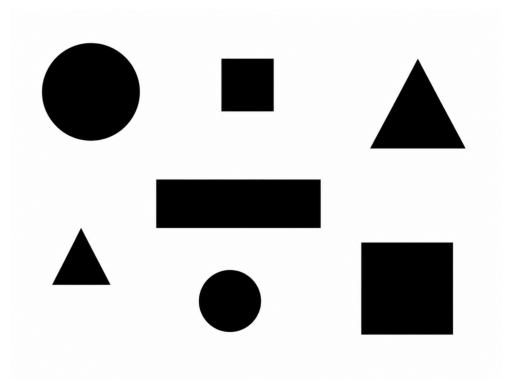

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

figury = cv2.imread("obraz_figury.jpg")
figury_rgb = cv2.cvtColor(figury, cv2.COLOR_BGR2RGB)
figury_szare = cv2.cvtColor(figury, cv2.COLOR_BGR2GRAY)
plt.imshow(figury_rgb)
plt.axis("off")
plt.show()

Liczba znalezionych konturow: 7


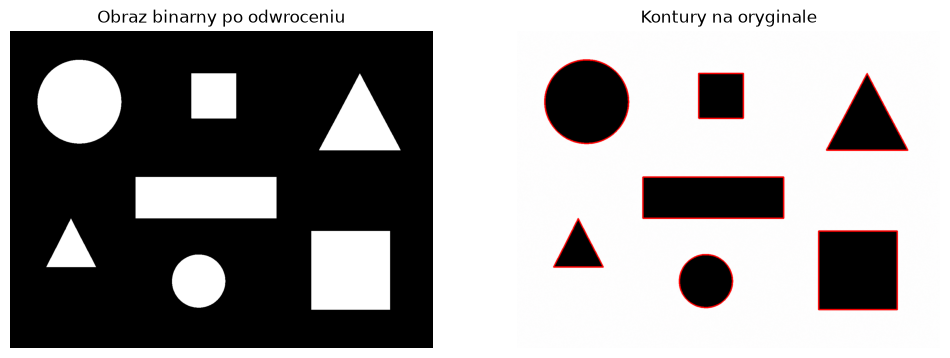

In [2]:
prog, binarny = cv2.threshold(figury_szare, 127, 255, cv2.THRESH_BINARY_INV)
kontury, hierarchia = cv2.findContours(
    binarny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
print("Liczba znalezionych konturow:", len(kontury))
z_konturami = figury_rgb.copy()
cv2.drawContours(z_konturami, kontury, -1, (255, 0, 0), 3)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny po odwroceniu")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(z_konturami)
plt.title("Kontury na oryginale")
plt.axis("off")
plt.show()

Kontur 0: pole = 25878, obwod = 602, prostokat = 183 x 182
Kontur 1: pole = 72361, obwod = 1076, prostokat = 270 x 270
Kontur 2: pole = 14017, obwod = 572, prostokat = 171 x 167
Kontur 3: pole = 67962, obwod = 1246, prostokat = 483 x 142
Kontur 4: pole = 36619, obwod = 919, prostokat = 279 x 264
Kontur 5: pole = 23561, obwod = 613, prostokat = 154 x 155
Kontur 6: pole = 64306, obwod = 949, prostokat = 288 x 287


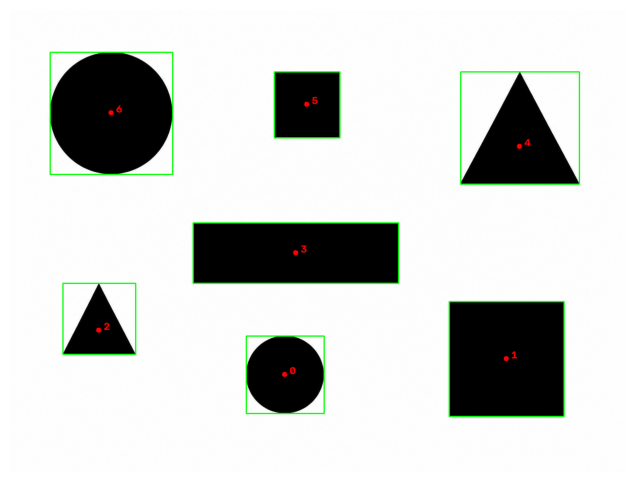

In [3]:
opisany = figury_rgb.copy()
for i, kontur in enumerate(kontury):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    x, y, w, h = cv2.boundingRect(kontur)

    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    cv2.rectangle(opisany, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(opisany, (cx, cy), 6, (255, 0, 0), -1)
    cv2.putText(
        opisany, str(i), (cx + 12, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2
    )

    print(f"Kontur {i}: pole = {pole:.0f}, obwod = {obwod:.0f}, prostokat = {w} x {h}")

plt.figure(figsize=(10, 6))
plt.imshow(opisany)
plt.axis("off")
plt.show()

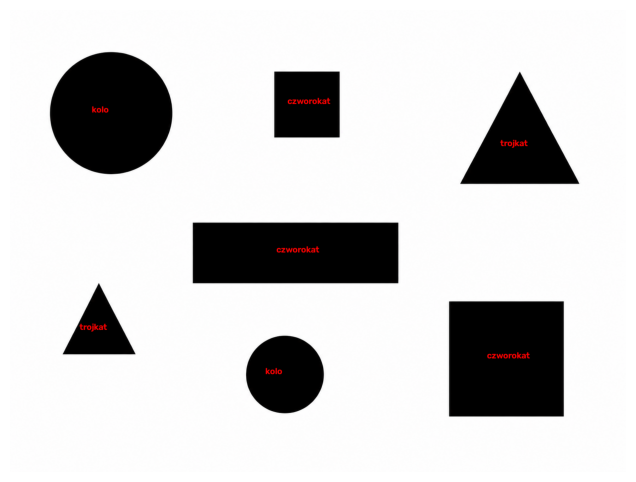

In [4]:
def rozpoznaj(kontur):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    kolistosc = 4 * np.pi * pole / (obwod**2)
    przyblizenie = cv2.approxPolyDP(kontur, 0.03 * obwod, True)
    wierzcholki = len(przyblizenie)
    if wierzcholki == 3:
        return "trojkat"
    if wierzcholki == 4:
        return "czworokat"
    if kolistosc > 0.85:
        return "kolo"
    return "inna"


rozpoznane = figury_rgb.copy()
for kontur in kontury:
    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    nazwa = rozpoznaj(kontur)
    cv2.putText(
        rozpoznane, nazwa, (cx - 45, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
    )
plt.figure(figsize=(10, 6))
plt.imshow(rozpoznane)
plt.axis("off")
plt.show()

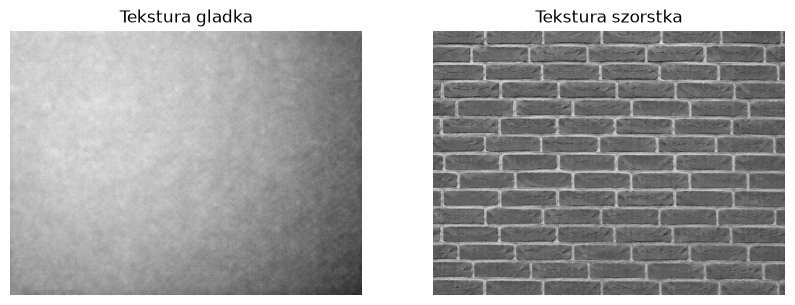

Gladka: srednia = 218.6 , odchylenie = 4.0
Szorstka: srednia = 113.2 , odchylenie = 32.4


In [5]:
gladka = cv2.imread("tekstura_gladka.jpg")
szorstka = cv2.imread("tekstura_szorstka.jpg")
gladka_szara = cv2.cvtColor(gladka, cv2.COLOR_BGR2GRAY)
szorstka_szara = cv2.cvtColor(szorstka, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gladka_szara, cmap="gray")
plt.title("Tekstura gladka")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(szorstka_szara, cmap="gray")
plt.title("Tekstura szorstka")
plt.axis("off")
plt.show()
print(
    "Gladka: srednia =",
    round(gladka_szara.mean(), 1),
    ", odchylenie =",
    round(gladka_szara.std(), 1),
)
print(
    "Szorstka: srednia =",
    round(szorstka_szara.mean(), 1),
    ", odchylenie =",
    round(szorstka_szara.std(), 1),
)

Ta sama tekstura: 1.0
Rozne tekstury: -0.14


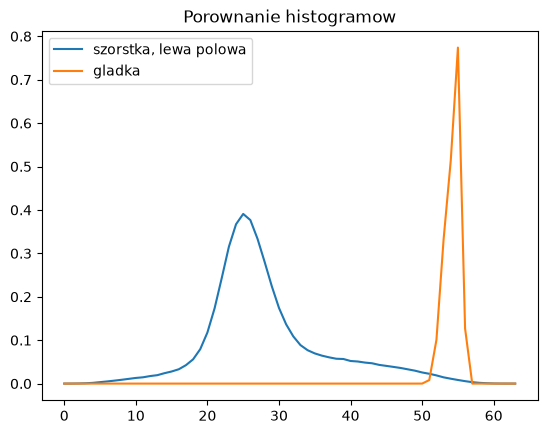

In [6]:
def histogram_znormalizowany(fragment):
    hist = cv2.calcHist([fragment], [0], None, [64], [0, 256])
    return cv2.normalize(hist, hist).flatten()


wys, szer = szorstka_szara.shape
lewa = szorstka_szara[:, : szer // 2]
prawa = szorstka_szara[:, szer // 2 :]
h_lewa = histogram_znormalizowany(lewa)
h_prawa = histogram_znormalizowany(prawa)
h_gladka = histogram_znormalizowany(gladka_szara)
print(
    "Ta sama tekstura:", round(cv2.compareHist(h_lewa, h_prawa, cv2.HISTCMP_CORREL), 2)
)
print(
    "Rozne tekstury:", round(cv2.compareHist(h_lewa, h_gladka, cv2.HISTCMP_CORREL), 2)
)
plt.plot(h_lewa, label="szorstka, lewa polowa")
plt.plot(h_gladka, label="gladka")
plt.title("Porownanie histogramow")
plt.legend()
plt.show()

# Zadanie 1

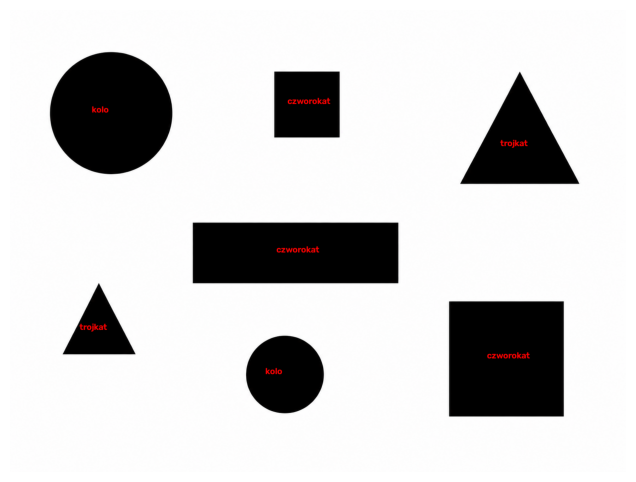

{'kolo': 2, 'czworokat': 3, 'trojkat': 2}


In [9]:
def rozpoznaj(kontur):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    kolistosc = 4 * np.pi * pole / (obwod**2)
    przyblizenie = cv2.approxPolyDP(kontur, 0.03 * obwod, True)
    wierzcholki = len(przyblizenie)
    if wierzcholki == 3:
        return "trojkat"
    if wierzcholki == 4:
        return "czworokat"
    if kolistosc > 0.85:
        return "kolo"
    return "inna"


figury_count = {}

rozpoznane = figury_rgb.copy()
for kontur in kontury:
    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    nazwa = rozpoznaj(kontur)
    cv2.putText(
        rozpoznane, nazwa, (cx - 45, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
    )
    figury_count[nazwa] = figury_count.get(nazwa, 0) + 1
plt.figure(figsize=(10, 6))
plt.imshow(rozpoznane)
plt.axis("off")
plt.show()

print(figury_count)

# Zadanie 2

Liczba znalezionych konturow: 82


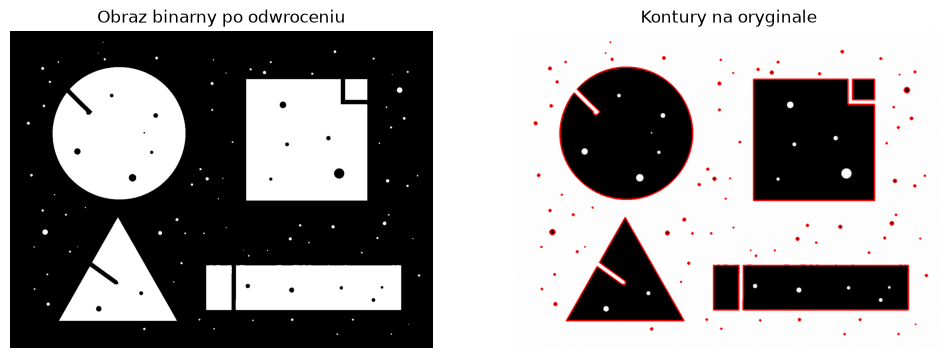

Kontur 0: pole = 12, obwod = 14, prostokat = 6 x 4
Kontur 1: pole = 16, obwod = 15, prostokat = 6 x 5
Kontur 2: pole = 14, obwod = 14, prostokat = 6 x 5
Kontur 3: pole = 42, obwod = 24, prostokat = 8 x 8
Kontur 4: pole = 2, obwod = 6, prostokat = 3 x 2
Kontur 5: pole = 14, obwod = 14, prostokat = 5 x 5
Kontur 6: pole = 26, obwod = 19, prostokat = 7 x 6
Kontur 7: pole = 20, obwod = 16, prostokat = 6 x 6
Kontur 8: pole = 44, obwod = 24, prostokat = 8 x 8
Kontur 9: pole = 80, obwod = 34, prostokat = 11 x 11
Kontur 10: pole = 20, obwod = 16, prostokat = 6 x 6
Kontur 11: pole = 10, obwod = 12, prostokat = 4 x 5
Kontur 12: pole = 37, obwod = 23, prostokat = 8 x 8
Kontur 13: pole = 23, obwod = 18, prostokat = 6 x 6
Kontur 14: pole = 86018, obwod = 1444, prostokat = 567 x 154
Kontur 15: pole = 13120, obwod = 483, prostokat = 88 x 154
Kontur 16: pole = 36, obwod = 23, prostokat = 8 x 8
Kontur 17: pole = 18, obwod = 16, prostokat = 6 x 6
Kontur 18: pole = 20, obwod = 16, prostokat = 6 x 6
Kontur

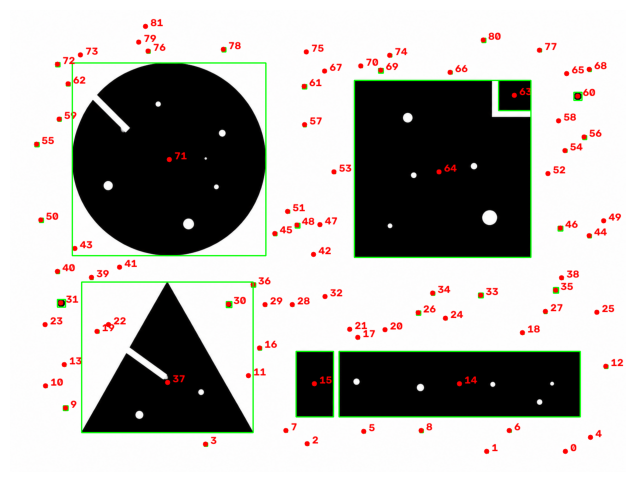

Liczba znalezionych konturow wiekszych niz 200: 8


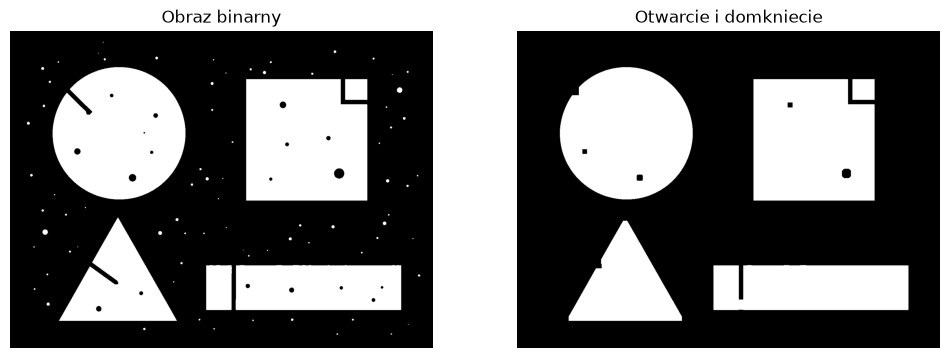

Liczba obiektów po oczyszczeniu: 5
Obiekt 0: pole = 99552, obwod = 1874, prostokat = 668 x 154
Obiekt 1: pole = 70880, obwod = 1253, prostokat = 388 x 343
Obiekt 2: pole = 5250, obwod = 290, prostokat = 76 x 71
Obiekt 3: pole = 163984, obwod = 1657, prostokat = 415 x 416
Obiekt 4: pole = 161001, obwod = 1514, prostokat = 455 x 453


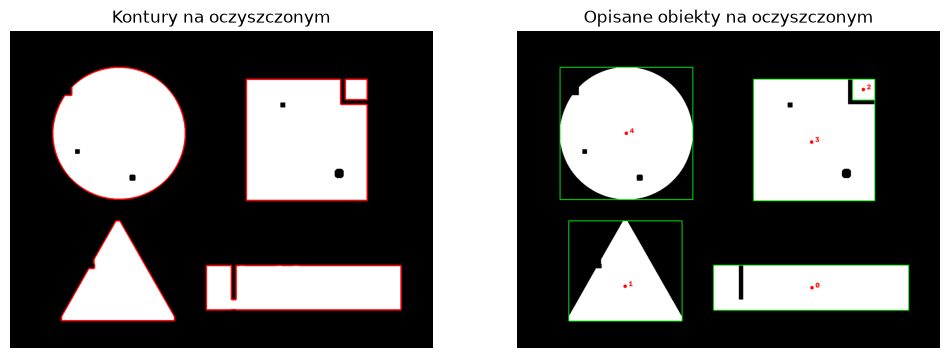

In [17]:
ksztalty = cv2.imread("obraz_ksztalty.jpg")
ksztalty_rgb = cv2.cvtColor(ksztalty, cv2.COLOR_BGR2RGB)
ksztalty_szare = cv2.cvtColor(ksztalty, cv2.COLOR_BGR2GRAY)

prog, binarny = cv2.threshold(ksztalty_szare, 127, 255, cv2.THRESH_BINARY_INV)
kontury, hierarchia = cv2.findContours(
    binarny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
print("Liczba znalezionych konturow:", len(kontury))
z_konturami = ksztalty_rgb.copy()
cv2.drawContours(z_konturami, kontury, -1, (255, 0, 0), 3)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny po odwroceniu")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(z_konturami)
plt.title("Kontury na oryginale")
plt.axis("off")
plt.show()

kontry_wieksze_200 = []

opisany = ksztalty_rgb.copy()
for i, kontur in enumerate(kontury):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    x, y, w, h = cv2.boundingRect(kontur)

    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    cv2.rectangle(opisany, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(opisany, (cx, cy), 6, (255, 0, 0), -1)
    cv2.putText(
        opisany, str(i), (cx + 12, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2
    )

    print(f"Kontur {i}: pole = {pole:.0f}, obwod = {obwod:.0f}, prostokat = {w} x {h}")

    if pole >= 200:
        kontry_wieksze_200.append(kontur)

plt.figure(figsize=(10, 6))
plt.imshow(opisany)
plt.axis("off")
plt.show()

print("Liczba znalezionych konturow wiekszych niz 200:", len(kontry_wieksze_200))

prog, binarny = cv2.threshold(ksztalty_szare, 127, 255, cv2.THRESH_BINARY_INV)

jadro = np.ones((15, 15), np.uint8)
otwarcie = cv2.morphologyEx(binarny, cv2.MORPH_OPEN, jadro)
oczyszczony = cv2.morphologyEx(otwarcie, cv2.MORPH_CLOSE, jadro)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(binarny, cmap="gray")
plt.title("Obraz binarny")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(oczyszczony, cmap="gray")
plt.title("Otwarcie i domkniecie")
plt.axis("off")
plt.show()

kontury_ocz, hierarchia = cv2.findContours(
    oczyszczony, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
print("Liczba obiektów po oczyszczeniu:", len(kontury_ocz))

oczyszczony_rgb = cv2.cvtColor(oczyszczony, cv2.COLOR_GRAY2RGB)

z_konturami = oczyszczony_rgb.copy()
cv2.drawContours(z_konturami, kontury_ocz, -1, (255, 0, 0), 3)

opisany = oczyszczony_rgb.copy()
for i, kontur in enumerate(kontury_ocz):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    x, y, w, h = cv2.boundingRect(kontur)

    m = cv2.moments(kontur)
    if m["m00"] == 0:
        continue
    cx = int(m["m10"] / m["m00"])
    cy = int(m["m01"] / m["m00"])

    cv2.rectangle(opisany, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(opisany, (cx, cy), 6, (255, 0, 0), -1)
    cv2.putText(
        opisany, str(i), (cx + 12, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2
    )

    print(f"Obiekt {i}: pole = {pole:.0f}, obwod = {obwod:.0f}, prostokat = {w} x {h}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(z_konturami)
plt.title("Kontury na oczyszczonym")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(opisany)
plt.title("Opisane obiekty na oczyszczonym")
plt.axis("off")
plt.show()

# Zadanie 3

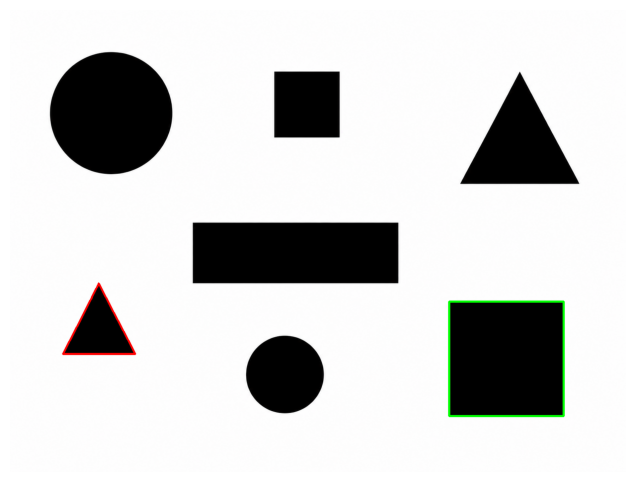

Największe pole: 72361.0
Najmniejsze pole: 14017.0


In [21]:
prog, binarny = cv2.threshold(figury_szare, 127, 255, cv2.THRESH_BINARY_INV)
kontury, hierarchia = cv2.findContours(
    binarny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

najwiekszy = max(kontury, key=cv2.contourArea)
najmniejszy = min(kontury, key=cv2.contourArea)

pole_max = cv2.contourArea(najwiekszy)
pole_min = cv2.contourArea(najmniejszy)

wynik = figury_rgb.copy()
cv2.drawContours(wynik, [najwiekszy], -1, (0, 255, 0), 4)
cv2.drawContours(wynik, [najmniejszy], -1, (255, 0, 0), 4)

plt.figure(figsize=(10, 6))
plt.imshow(wynik)
plt.axis("off")
plt.show()

print(f"Największe pole: {pole_max}")
print(f"Najmniejsze pole: {pole_min}")

# Zadanie 4

270 270
483 142
154 155


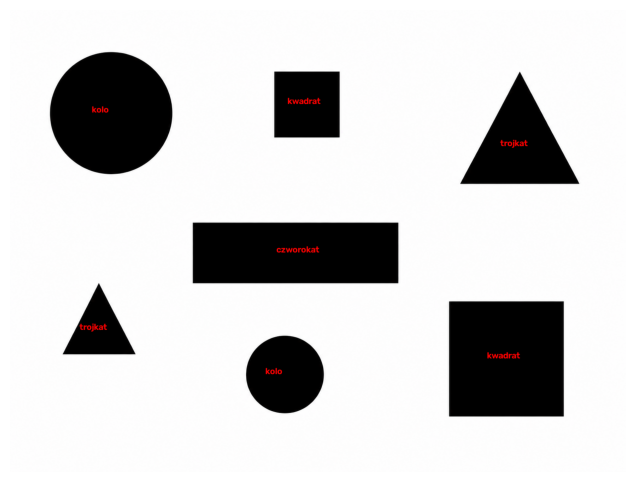

{'kolo': 2, 'kwadrat': 2, 'trojkat': 2, 'czworokat': 1}


In [ ]:
def rozpoznaj(kontur):
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    kolistosc = 4 * np.pi * pole / (obwod**2)
    przyblizenie = cv2.approxPolyDP(kontur, 0.03 * obwod, True)
    wierzcholki = len(przyblizenie)
    if wierzcholki == 3:
        return "trojkat"
    if wierzcholki == 4:
        _x, _y, w, h = cv2.boundingRect(kontur)
        print(w, h)
        if w / h < 1.1 and w / h > 0.9:
            return "kwadrat"
        return "czworokat"
    if kolistosc > 0.85:
        return "kolo"
    return "inna"


figury_count = {}

rozpoznane = figury_rgb.copy()
for kontur in kontury:
    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    nazwa = rozpoznaj(kontur)
    cv2.putText(
        rozpoznane, nazwa, (cx - 45, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2
    )
    figury_count[nazwa] = figury_count.get(nazwa, 0) + 1
plt.figure(figsize=(10, 6))
plt.imshow(rozpoznane)
plt.axis("off")
plt.show()

print(figury_count)

# Zadanie 5 

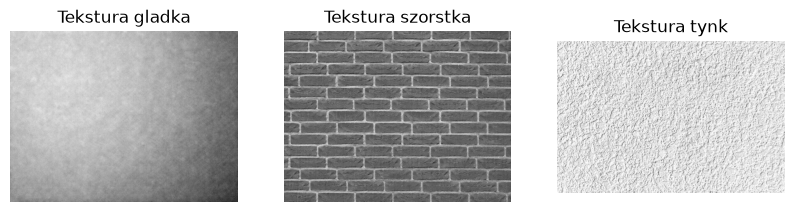

Gladka: srednia = 218.6 , odchylenie = 4.0
Szorstka: srednia = 113.2 , odchylenie = 32.4
Tynk: srednia = 224.0 , odchylenie = 26.5
Ta sama tekstura: 1.0
Rozne tekstury: -0.14
tynk vs gladka: 0.3
tynk vs lewa: -0.35


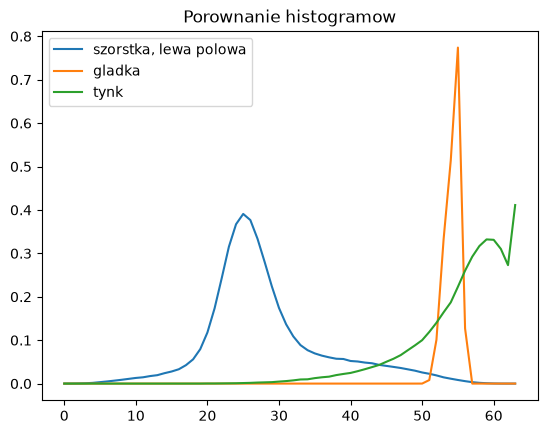

In [ ]:
gladka = cv2.imread("tekstura_gladka.jpg")
szorstka = cv2.imread("tekstura_szorstka.jpg")
tynk = cv2.imread("tekstura_tynk.jpg")
gladka_szara = cv2.cvtColor(gladka, cv2.COLOR_BGR2GRAY)  # type: ignore
szorstka_szara = cv2.cvtColor(szorstka, cv2.COLOR_BGR2GRAY)  # type: ignore
tynk_szara = cv2.cvtColor(tynk, cv2.COLOR_BGR2GRAY)  # type: ignore
plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(gladka_szara, cmap="gray")
plt.title("Tekstura gladka")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(szorstka_szara, cmap="gray")
plt.title("Tekstura szorstka")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(tynk_szara, cmap="gray")
plt.title("Tekstura tynk")
plt.axis("off")
plt.show()
print(
    "Gladka: srednia =",
    round(gladka_szara.mean(), 1),
    ", odchylenie =",
    round(gladka_szara.std(), 1),
)
print(
    "Szorstka: srednia =",
    round(szorstka_szara.mean(), 1),
    ", odchylenie =",
    round(szorstka_szara.std(), 1),
)
print(
    "Tynk: srednia =",
    round(tynk_szara.mean(), 1),
    ", odchylenie =",
    round(tynk_szara.std(), 1),
)


def histogram_znormalizowany(fragment):
    hist = cv2.calcHist([fragment], [0], None, [64], [0, 256])
    return cv2.normalize(hist, hist).flatten()


wys, szer = szorstka_szara.shape
lewa = szorstka_szara[:, : szer // 2]
prawa = szorstka_szara[:, szer // 2 :]
h_lewa = histogram_znormalizowany(lewa)
h_prawa = histogram_znormalizowany(prawa)
h_gladka = histogram_znormalizowany(gladka_szara)
h_tynk = histogram_znormalizowany(tynk_szara)
print(
    "Ta sama tekstura:", round(cv2.compareHist(h_lewa, h_prawa, cv2.HISTCMP_CORREL), 2)
)
print(
    "Rozne tekstury:", round(cv2.compareHist(h_lewa, h_gladka, cv2.HISTCMP_CORREL), 2)
)
print(
    "tynk vs gladka:", round(cv2.compareHist(h_tynk, h_gladka, cv2.HISTCMP_CORREL), 2)
)
print("tynk vs lewa:", round(cv2.compareHist(h_tynk, h_lewa, cv2.HISTCMP_CORREL), 2))
plt.plot(h_lewa, label="szorstka, lewa polowa")
plt.plot(h_gladka, label="gladka")
plt.plot(h_tynk, label="tynk")
plt.title("Porownanie histogramow")
plt.legend()
plt.show()

# Zadanie dodatkowe

Kontur 1: pole = 72361, obwod = 1076, prostokat = 270 x 270
Kontur 2: pole = 67962, obwod = 1246, prostokat = 483 x 142
Kontur 3: pole = 64306, obwod = 949, prostokat = 288 x 287
Kontur 4: pole = 36619, obwod = 919, prostokat = 279 x 264
Kontur 5: pole = 25878, obwod = 602, prostokat = 183 x 182
Kontur 6: pole = 23561, obwod = 613, prostokat = 154 x 155
Kontur 7: pole = 14017, obwod = 572, prostokat = 171 x 167


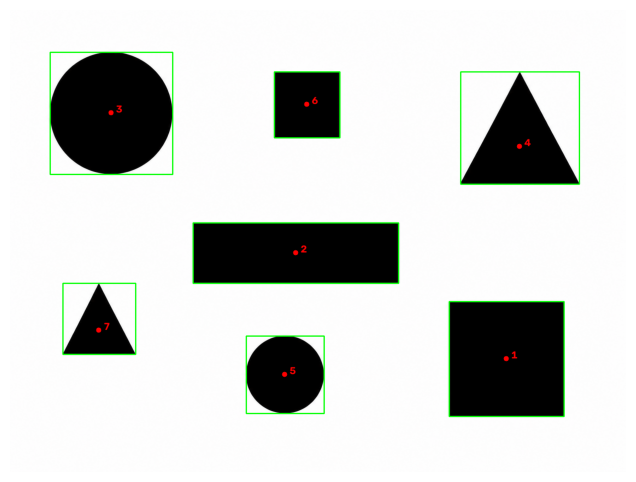

In [ ]:
opisany = figury_rgb.copy()

kontury_sort = sorted(kontury, key=cv2.contourArea, reverse=True)

for i, kontur in enumerate(kontury_sort):
    i = i + 1
    pole = cv2.contourArea(kontur)
    obwod = cv2.arcLength(kontur, True)
    x, y, w, h = cv2.boundingRect(kontur)

    momenty = cv2.moments(kontur)
    cx = int(momenty["m10"] / momenty["m00"])
    cy = int(momenty["m01"] / momenty["m00"])
    cv2.rectangle(opisany, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(opisany, (cx, cy), 6, (255, 0, 0), -1)
    cv2.putText(
        opisany, str(i), (cx + 12, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2
    )

    print(f"Kontur {i}: pole = {pole:.0f}, obwod = {obwod:.0f}, prostokat = {w} x {h}")

plt.figure(figsize=(10, 6))
plt.imshow(opisany)
plt.axis("off")
plt.show()